# 05 · Feature engineering — Aluguel São Paulo (capital)

**Entrada:** `data/interim/aluguel_sp_poi.parquet` (notebook 03).
**Saída:** `data/interim/aluguel_sp_features.parquet` — features + colunas de split (`split`, `grupo_espacial`, `imovel_key`).

A lógica das features fica em [`src/features/aluguel.py`](../../src/features/aluguel.py), não no notebook: o modelo salvo em pickle (06) e, depois, o treino no MLflow e a API precisam **importar** os mesmos transformers.

### O que os notebooks 01–04 pediram
| Achado | Feature |
|---|---|
| Elasticidade da área < 1 (02) | `log_area`, `area_por_quarto`, `banheiros_por_quarto` |
| Pico de preço a ~4 km da Sé, não no marco zero (01, 02) | distância a **polos de valor** (Faria Lima, Paulista, Berrini) + coordenadas rotacionadas |
| Região memoriza, POIs generalizam (04) | região via **target encoding** + 26 features de POI |
| Resíduo ainda correlacionado com vizinhos (02, 04) | **preço da vizinhança**: R$/m² dos k anúncios mais próximos, sem o próprio |
| Metrô tem gradiente (04) | log da distância ao metrô / transporte |
| Condomínio + IPTU: decisão pendente (01, 02) | `log_condominio` — entra só no conjunto S5, para comparar |

### Regra contra vazamento
- Features **sem alvo** (distâncias, razões, rotações) são criadas aqui, antes do split.
- Features **com alvo** (target encoding de região, preço da vizinhança) são transformers do sklearn e são ajustadas **dentro** de cada fold no 06.

## 1. Setup e carga

In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupShuffleSplit

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.options.display.float_format = "{:,.3f}".format
sns.set_theme(style="whitegrid", context="notebook")
COR, CINZA, RNG = "#2a6f97", "#c0c7cf", 42


def achar_raiz(marcador: str = ".git") -> Path:
    p = Path.cwd().resolve()
    for candidato in [p, *p.parents]:
        if (candidato / marcador).exists():
            return candidato
    raise FileNotFoundError(f"Raiz do projeto ({marcador}) não encontrada a partir de {p}")


ROOT = achar_raiz()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features import aluguel as fa

df = pd.read_parquet(ROOT / "data/interim/aluguel_sp_poi.parquet")
print(df.shape)

(22213, 146)


## 2. Features determinísticas

In [5]:
df = fa.criar_features(df)
df["log_rent_m2"] = df[fa.TARGET] - df["log_area"]      # só para análise (não é feature)

blocos = {
    "Planta": fa.PLANTA,
    "Atributos": fa.ATRIBUTOS,
    "Amenities / instalações": fa.colunas_amenities(df),
    "Localização": fa.LOCAL,
    "POIs": fa.POI,
    "Condomínio": fa.CONDOMINIO,
}
pd.DataFrame({"nº features": {k: len(v) for k, v in blocos.items()},
              "exemplos": {k: ", ".join(v[:4]) + (" ..." if len(v) > 4 else "") for k, v in blocos.items()}})

,nº features,exemplos
Planta,7,"log_area, bedrooms, bathrooms, suites ..."
Atributos,5,"mobiliado, n_amenities, n_instalacoes, cond_ex..."
Amenities / instalações,73,"am_acesso_sem_degraus, am_apartamento_cobertur..."
Localização,15,"lat, lon, dist_centro_km, dist_polo_km ..."
POIs,26,"logdist_escola_publica, logdist_escola_privada..."
Condomínio,1,log_condominio


### 2.1 Polos de valor × marco zero

O 02 mostrou que o preço **sobe** até ~4 km da Sé e depois cai. A hipótese é que o preço gira em torno dos polos de emprego, não do centro histórico.

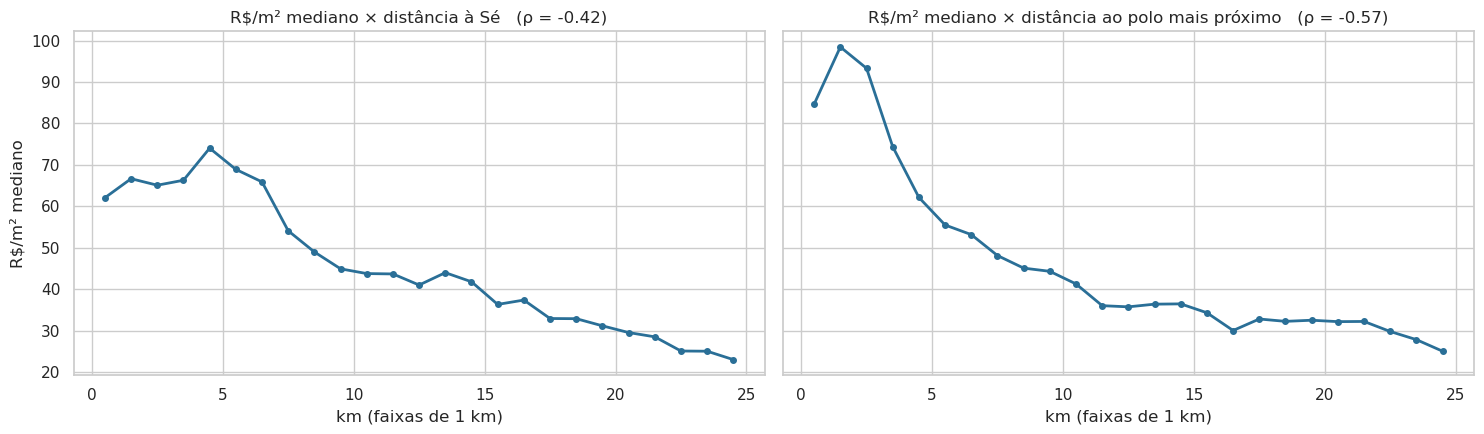

Spearman com log(R$/m²):
dist_centro_km       -0.421
dist_polo_km         -0.575
dist_faria_lima_km   -0.568
dist_paulista_km     -0.538
dist_berrini_km      -0.496


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, col, nome in [(axes[0], "dist_centro_km", "distância à Sé"), (axes[1], "dist_polo_km", "distância ao polo mais próximo")]:
    b = df[col].clip(upper=24.99).floordiv(1) + 0.5
    g = df.groupby(b)["log_rent_m2"].agg(mediana="median", n="size").query("n >= 30")
    ax.plot(g.index, np.exp(g["mediana"]), color=COR, lw=2, marker="o", ms=4)
    rho = stats.spearmanr(df[col], df["log_rent_m2"])[0]
    ax.set_title(f"R$/m² mediano × {nome}   (ρ = {rho:.2f})")
    ax.set_xlabel("km (faixas de 1 km)")
axes[0].set_ylabel("R$/m² mediano")
plt.tight_layout()
plt.show()

esp = pd.Series({c: stats.spearmanr(df[c], df["log_rent_m2"])[0]
                 for c in ["dist_centro_km", "dist_polo_km", *[f"dist_{n}_km" for n in fa.POLOS]]})
print("Spearman com log(R$/m²):")
print(esp.round(3).to_string())

## 3. Preço da vizinhança (k vizinhos mais próximos)

Para cada anúncio: média e mediana de log(R$/m²) dos **k anúncios de treino mais próximos** e a distância média até eles.

**Cuidado de vazamento:** no treino, o próprio anúncio precisa ser excluído dos vizinhos. Abaixo, a diferença entre incluir e excluir — e a escolha de k.

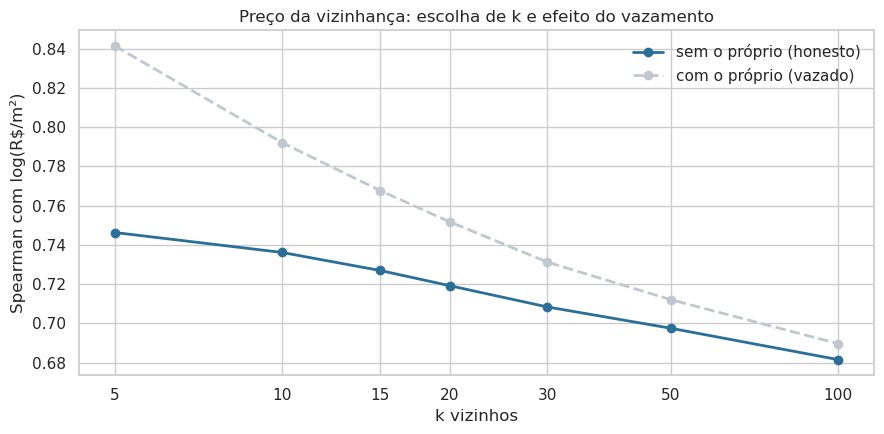

k escolhido (maior correlação honesta): 5


,ρ sem o próprio (honesto),ρ com o próprio (vazado)
k,,
5,0.746,0.841
10,0.736,0.792
15,0.727,0.768
20,0.719,0.752
30,0.708,0.731
50,0.698,0.712
100,0.682,0.690


In [7]:
X_knn = df[["lat", "lon", "log_area"]]
y = df[fa.TARGET]

linhas = []
for k in [5, 10, 15, 20, 30, 50, 100]:
    enc = fa.KNNTargetEncoder(k=k)
    sem = enc.fit_transform(X_knn, y)[:, 0]
    com = enc.transform(X_knn)[:, 0]             # inclui o próprio anúncio (errado no treino)
    linhas.append({"k": k,
                   "ρ sem o próprio (honesto)": stats.spearmanr(sem, df["log_rent_m2"])[0],
                   "ρ com o próprio (vazado)": stats.spearmanr(com, df["log_rent_m2"])[0]})
esc_k = pd.DataFrame(linhas).set_index("k")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(esc_k.index, esc_k["ρ sem o próprio (honesto)"], marker="o", color=COR, lw=2, label="sem o próprio (honesto)")
ax.plot(esc_k.index, esc_k["ρ com o próprio (vazado)"], marker="o", color=CINZA, lw=2, ls="--", label="com o próprio (vazado)")
ax.set_xscale("log")
ax.set_xticks(esc_k.index, esc_k.index)
ax.set_xlabel("k vizinhos")
ax.set_ylabel("Spearman com log(R$/m²)")
ax.set_title("Preço da vizinhança: escolha de k e efeito do vazamento")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

K_ESCOLHIDO = int(esc_k["ρ sem o próprio (honesto)"].idxmax())
print(f"k escolhido (maior correlação honesta): {K_ESCOLHIDO}")
esc_k.round(3)

> Com k pequeno, incluir o próprio anúncio infla muito a correlação: o modelo veria parte do próprio alvo.
> O k final também entra na busca de hiperparâmetros do 06.

## 4. Redundância entre features

Pares com |ρ| > 0,95 carregam a mesma informação. Árvores lidam bem com isso; nos modelos lineares a regularização (Ridge) distribui o peso.
Aqui só registramos — remover cegamente pode tirar informação útil para um tipo de modelo.

In [8]:
fs_all = fa.conjuntos_features(df)["S5 · + condomínio"]["num"]
num_cont = [c for c in fs_all if df[c].nunique() > 2]
corr = df[num_cont].corr(method="spearman").abs()
tri = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pares = tri.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print(f"{len(pares)} pares com |ρ| > 0,95 entre {len(num_cont)} features contínuas")
pares.head(20).rename("|ρ|").to_frame()

8 pares com |ρ| > 0,95 entre 51 features contínuas


,,|ρ|
rot45_y,rot60_y,0.985
rot30_y,rot45_y,0.981
lon,rot15_x,0.977
dist_polo_km,dist_faria_lima_km,0.969
rot15_x,rot30_x,0.969
rot15_y,rot30_y,0.963
rot30_x,rot45_x,0.960
logdist_metro,logacess_metro,0.951


## 5. Estratégia de validação

| Peça | Como | Por quê |
|---|---|---|
| **Holdout (teste)** | 20% dos anúncios, sorteados por `imovel_key` | O mesmo imóvel re-anunciado com outro preço (notebook 01) não pode cair em treino e teste |
| **CV aleatória** (no treino) | `GroupKFold(5, shuffle)` por `imovel_key` | Cenário de produção: novos anúncios em áreas conhecidas |
| **CV espacial** (no treino) | 30 clusters de lat/lon (KMeans) → `GroupKFold(5)` | Teste de estresse: áreas inteiras nunca vistas. Escolha do modelo usa esta |

O holdout é usado **uma única vez**, no fim do 06.

In [9]:
df["imovel_key"] = pd.factorize(
    df["lat"].round(5).astype(str) + "|" + df["lon"].round(5).astype(str) + "|" +
    df["area"].astype(str) + "|" + df["bedrooms"].astype(str)
)[0]
print(f"Anúncios: {len(df):,} | imóveis distintos (imovel_key): {df['imovel_key'].nunique():,}")

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RNG)
idx_tr, idx_te = next(gss.split(df, groups=df["imovel_key"]))
df["split"] = "treino"
df.loc[df.index[idx_te], "split"] = "teste"

df["grupo_espacial"] = KMeans(n_clusters=30, n_init=10, random_state=RNG).fit_predict(np.radians(df[["lat", "lon"]]))

print(df["split"].value_counts().to_string())
comp = df.groupby("split")["rent"].describe(percentiles=[.1, .5, .9])[["count", "mean", "10%", "50%", "90%"]]
comp

Anúncios: 22,213 | imóveis distintos (imovel_key): 19,981
split
treino    17739
teste      4474


,count,mean,10%,50%,90%
split,,,,,
teste,"4,474.000","4,116.890","1,400.000","2,800.000","8,121.000"
treino,"17,739.000","4,063.063","1,400.000","2,790.000","8,130.000"


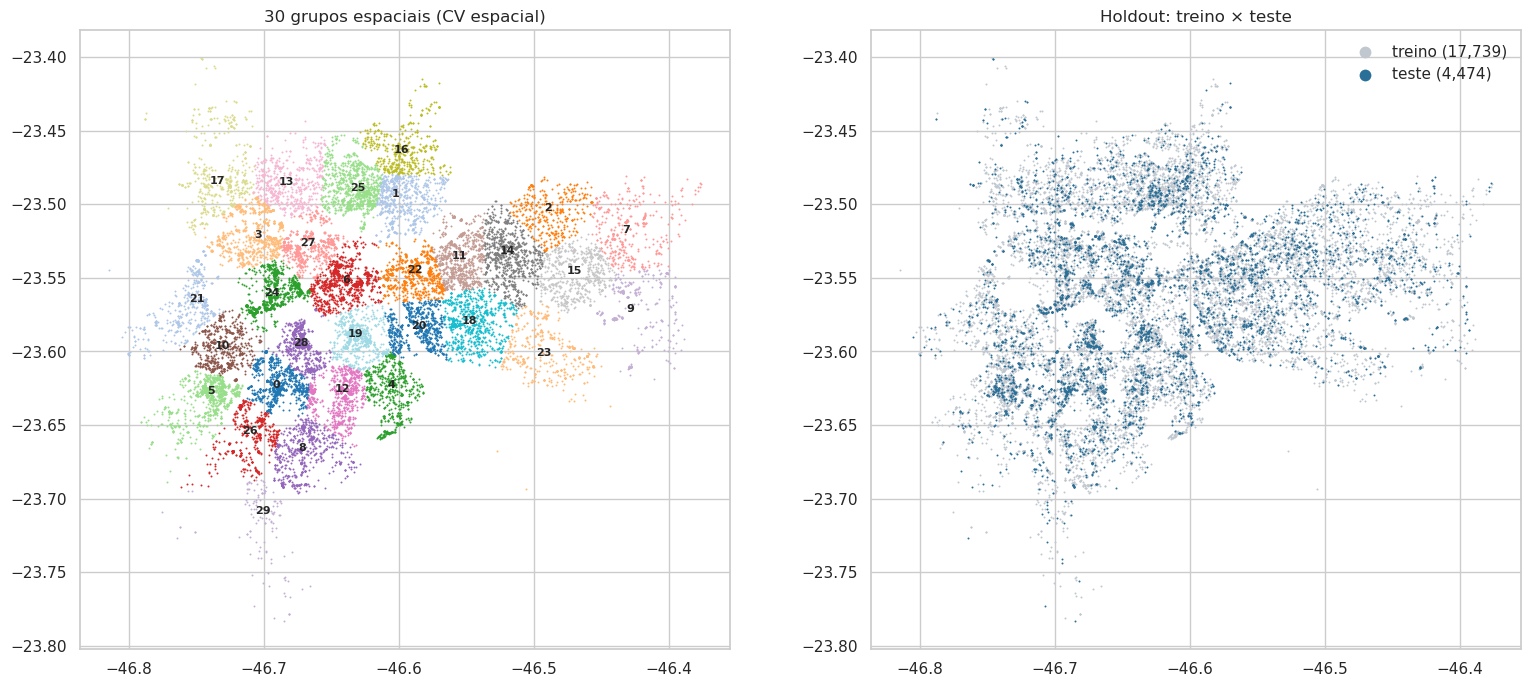

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
pal = sns.color_palette("tab20", 30)
for g in range(30):
    s = df[df["grupo_espacial"] == g]
    axes[0].scatter(s["lon"], s["lat"], s=2, color=pal[g], linewidths=0)
    axes[0].annotate(str(g), (s["lon"].median(), s["lat"].median()), fontsize=8, ha="center", weight="bold")
axes[0].set_aspect(1 / np.cos(np.radians(-23.55)))
axes[0].set_title("30 grupos espaciais (CV espacial)")

for nome, cor in [("treino", CINZA), ("teste", COR)]:
    s = df[df["split"] == nome]
    axes[1].scatter(s["lon"], s["lat"], s=2, color=cor, linewidths=0, label=f"{nome} ({len(s):,})")
axes[1].set_aspect(1 / np.cos(np.radians(-23.55)))
axes[1].set_title("Holdout: treino × teste")
axes[1].legend(frameon=False, markerscale=6)
plt.tight_layout()
plt.show()

## 6. Conjuntos de features (grade do 06)

Os conjuntos são **cumulativos**: a diferença de erro entre um e o próximo mede quanto aquele bloco agrega.

| Conjunto | Inclui |
|---|---|
| **S1 · imóvel** | planta, atributos, amenities, tipo — só o que está no anúncio |
| **S2 · + localização** | lat/lon, rotações, distâncias ao centro e aos polos, região (target encoding) |
| **S3 · + POIs** | distância e acessibilidade dos 12 POIs, transporte, mix escolar |
| **S4 · + vizinhança** | preço dos k vizinhos (encoder dentro do fold) |
| **S5 · + condomínio** | `log_condominio` — exige que o usuário informe o valor na UI |

In [11]:
conj = fa.conjuntos_features(df)
pd.DataFrame({
    "numéricas": {k: len(v["num"]) for k, v in conj.items()},
    "categóricas": {k: ", ".join(v["cat"]) for k, v in conj.items()},
    "vizinhança kNN": {k: "sim" if v["knn"] else "—" for k, v in conj.items()},
})

,numéricas,categóricas,vizinhança kNN
S1 · imóvel,85,type,—
S2 · + localização,100,"type, regiao",—
S3 · + POIs,126,"type, regiao",—
S4 · + vizinhança,126,"type, regiao",sim
S5 · + condomínio,127,"type, regiao",sim


## 7. Resumo

_(preenchido após execução)_

## 8. Salvar

In [ ]:
OUT = ROOT / "data/interim/aluguel_sp_features.parquet"
df.drop(columns=["log_rent_m2"]).to_parquet(OUT, index=False)
print(f"{OUT.relative_to(ROOT)} -> {df.shape}")
import json
CFG = ROOT / "results/features/aluguel_config.json"
CFG.parent.mkdir(parents=True, exist_ok=True)
CFG.write_text(json.dumps({"k_vizinhos": K_ESCOLHIDO, "n_grupos_espaciais": 30, "seed": RNG}, indent=2))
print(f"k vizinhos sugerido para o 06: {K_ESCOLHIDO}  ->  {CFG.relative_to(ROOT)}")